# 02 · StatevectorSampler QNN — ikinci deneme

**Amaç:** İlk sürümdeki eğitim ve gradyan kodunu yeniden düzenleyerek deney akışını geliştirmek.

**Okuma notu:** 01 ile aynı ikili problem. Bu sürüm tüm yöntem sorunlarını çözmüş kabul edilmemelidir. Örnekleme ve rastgelelik nedeniyle sürüm numarası performans artışı anlamına gelmez.

**Durum:** Staj çalışması arşivi. Aşağıdaki çıktılar ZIP içinde kayıtlı geçmiş çalıştırmalara aittir; bu yayına hazırlık sırasında üretilmiş yeni deney sonuçları değildir. Deney kodu ve eski açıklamalar gelişim sürecini göstermek için korunmuştur; yöntem düzeltmeleri ve sınırlılıklar için [çalışma rehberini](../../docs/CALISMA_REHBERI.md), [sonuçları](../../docs/SONUCLAR.md) ve [yöntem incelemesini](../../docs/YONTEM_VE_SINIRLAR.md) okuyun.

**English:** Historical internship experiment. See the [English overview](../../README_EN.md). Saved outputs are historical evidence, not a fresh reproducibility claim.



## Hedef: Basit bir QNN ile iris veri kümesi üzerinde 2'li sınıflandırma yaparak simülasyonda çalıştırmak.

### Bu versiyon ilkine göre daha iyi sonuçlar veriyor çünkü kodlar üzerinde değişiklik yaptım ilk olarak statevectorsample kullanırken gereçkten kullandım. Sadece anlık çalışsın diye yaptığım yamaları değiştirerek amacına uygun ve daha az mantık hatalı bir hale getirdim.

Ancak bu kodun içerisinde hala çok fazla mantık hatası, yanlışlık veya düzeltilmesi gereken yönler bulabilirsiniz. 

%1'lik ilerleme olarak görüyorum şahsen


Öncelikle QML Kodlarının simülasyonda çalıştırılmasının birkaç temel nedeni var. IBM, Google gibi firmaların kuantum bilgisayarları gerçek donanımda (hardware) çok kısıtlı, gürültülü (noise) ve sıra beklemeli (queue). Bu nedenle; Kodun çalışması, eğitim süreci ve mantık klasik bilgisayarda kuantum bilgisayarı taklit eden yazılımla test ediliyor. 

Bu çalışmada kullanılan StatevectorSampler, devrenin ideal ve gürültüsüz davranışını doğrudan durum vektörü (statevector) üzerinden hesaplayabilir. Böylece her olası ölçüm sonucunun genliklerini eksiksiz elde eder, modeli hızlı, deterministik ve tekrarlı ölçüme (shots) ihtiyaç duymadan analiz eder. 

Bu, devre doğrulama, hata ayıklama ve teorik performans sınırını görmek için en uygun yaklaşımdır.

* StatevectorSampler: Teorik analiz, devre doğrulama, hiperparametre keşfi, küçük devreler → hızlı ve gürültüsüz temel.

* Aer (gürültüsüz/gürültülü): Gerçekçi performans tahmini, donanıma hazırlık, ölçüm istatistiği → pratik uygulanabilirlik.

* IBM Donanımı: Son doğrulama ve saha gerçekliği → nihai performans ve donanım etkileri.

Bu projede StatevectorSampler, modeli ideal ve deterministik koşullarda hızlıca değerlendirmemi sağladı; Aer ve IBM donanımı ise ölçüm istatistiği ve gürültü nedeniyle daha gerçekçi ama değişken sonuçlar üretir.




In [126]:
# environmentta yüklü değilse veya kaggle üzerinde
!pip install qiskit
!pip install pylatexenc # LaTeX çıktıları için gerekli

154703.05s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


154708.84s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


In [ ]:
import sklearn
import qiskit
import numpy as np
import matplotlib

print("scikit-learn version:", {sklearn.__version__})
print("Qiskit version:", {qiskit.__version__})
print("NumPy version:", {np.__version__})
print("Matplotlib version:", {matplotlib.__version__})

#scikit-learn version: {'1.7.1'}
#Qiskit version: {'1.2.4'}
#NumPy version: {'2.1.3'}
#Matplotlib version: {'3.10.5'}

scikit-learn version: {'1.7.1'}
Qiskit version: {'1.2.4'}
NumPy version: {'2.1.3'}
Matplotlib version: {'3.10.5'}


In [ ]:
from sklearn import model_selection, datasets, svm # klasik ML
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
#from qiskit.primitives import Sampler, Estimator 3 ay sonra kullanımdan kalkıyor
from qiskit.primitives import StatevectorSampler, StatevectorEstimator # Qiskit primitives
import numpy as np
import matplotlib.pyplot as plt 

**QuantumRegister:** Qubitleri içerir, yani kuantum bilgisayarın asıl işlem yapan birimleri.

**ClassicalRegister:** Ölçüm sonuçlarının tutulduğu klasik bitler.

**QuantumCircuit:** Kuantum Devresi. Qubitler üzerinde kapılar/operasyonlar uygulanır, sonunda ölçüm yapılıp sonuçlar ClassicalRegister’a aktarılır.

Yani devre, **QuantumRegister** üstünde çalışır ve çıktılarını **ClassicalRegister**’a kaydeder.

In [21]:
iris = datasets.load_iris()  # Iris veri kümesini yükledik

X = iris.data[0:100]
Y = iris.target[0:100]

# iris veri kümesinde 150 gözlem, 3 farklı sınıf (setosa, versicolor, virginica) var.
# İlk 100 gözlem alınıyor. Yani sadece ilk iki sınıf (setosa = 0, versicolor = 1).
#Böylece problem binary classification haline getiriliyor.

X_train, X_test, Y_train, Y_test = model_selection.train_test_split(
    X, Y, test_size=0.33, random_state=42
)

- **X (features / bağımsız değişkenler):**
    
    Modelin girdi olarak aldığı veriler → mesela iris çiçeğinin 4 ölçümü.
    
- **Y (labels / bağımlı değişken):**
    
    Modelin tahmin etmeye çalıştığı hedef → mesela çiçek türü (0 veya 1).
    

**train_test_split(X, Y, ...) :**

X_train → eğitimde kullanılacak girdiler

Y_train → eğitimde kullanılacak etiketler

X_test → testte kullanılacak girdiler

Y_test → testte kullanılacak etiketler

| X (özellikler)        | Y (etiket) |
| --------------------- | ---------- |
| \[5.1, 3.5, 1.4, 0.2] | 0          |
| \[7.0, 3.2, 4.7, 1.4] | 1          |


In [22]:
print(X_train[0])
# iris veri setinde her bir gözlem 4 özellikten oluşmaktadır: 
# Sepal Lenght, sepal width, petal lenght, petal width

[5.2 3.4 1.4 0.2]


QML'de her bir özelliği bir qubit'e encode ederiz. Özellikle küşük veri setlerinde en anlaşılır yöntem budur.

Veri boyutu büyüdükçe (örn 100 feature) çok fazla qubit gerekir ve bu donanımda büyük sorunlar yaratır. Bu yüzden ileri encoding yöntemleri geliştirilmiştir. (amplitude encoding, angle encoding)

In [23]:
N = 4  # Özellik sayısı (her özellik için bir qubit kullanacağız)
q = QuantumRegister(N)       # N qubitlik kuantum register (girdi)
c = ClassicalRegister(1)     # 1 bitlik klasik register (çıktı), ölçüm sonucunu kaydetmek için
qc = QuantumCircuit(q, c)    # Kuantum devresini oluştur

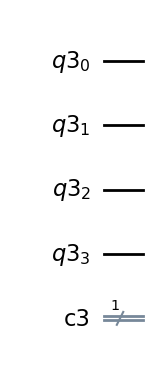

In [24]:
qc.draw("mpl")  # Devreyi görselleştir

Bu basit bir devre

**4 qubit** → giriş özelliklerini encode edeceğin yer.

**1 klasik bit** → ölçüm sonucunu tutacağın yer (modelin tahmini).

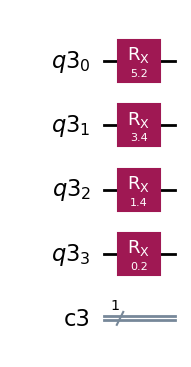

In [25]:
# Feature Encoding
# İlk gözlemin her bir özellik değerini qubit'e yüklemek için,
# RX kapısı uyguluyoruz

for i, x in enumerate(X_train[0]):
    qc.rx(x, i)

qc.draw("mpl")


Yaptığımız işlemi bir fonksiyon haline getirelim

In [26]:
N=4

def feature_map(X):

    q = QuantumRegister(N)
    c = ClassicalRegister(1)
    qc = QuantumCircuit(q, c)

    for i, x in enumerate(X):
        qc.rx(x, i)
    return qc, c

# Bu fonksiyonla feature_map(X) fonksiyonu = girdi vektörünü al, 
# N qubit’e rotation kapılarıyla encode et, devreyi döndür.

# Qislitin hazır feature map sınıfları var, (örn. ZZFeatureMap, PauliFeatureMap).
# Onlar da aynı mantığı içeride döngüyle yapıyor, ama daha gelişmiş versiyonlar.

Kuantum Devresini oluşturduk, ve bu devreyi ölçmemiz gerekiyor çünkü bir çıktı elde etmeliyiz.

Devreyi çalıştırıp sadece qubitleri döndürmek yetmez. En sonunda ölçüm (measurement) yaparak qubit’in kuantum durumunu klasik bir sayıya (0 veya 1) dönüştürmemiz gerekir.

Bu ölçüm(çıktı) bizim quantum devremizin tahmini olacak. 

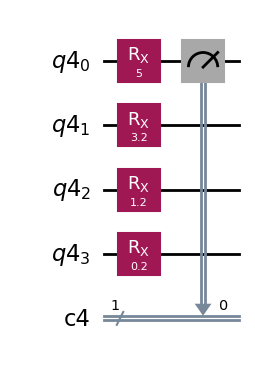

In [27]:
qc, c = feature_map(X_train[5])   # 6. gözlemi feature_map fonksiyonuyla ile devreye encode et
qc.measure(0, c)  # q0 qubitini ölç ve sonucu c’ye (classical register) yaz
qc.draw("mpl")

#### **qc.measure(0, c)**

q0 qubitini ölç ve Ölçüm sonucucunu c (classical register) içine yaz.
Sonuç ya 0 ya da 1 olur.


#### **Neden 4’ünü birden ölçmüyoruz?**

Ölçmek, kuantum bilgisayarda “klasik bilgiye çevirme” demek.

Eğer tüm qubitleri ölçersen, her birinden bir bit alırsın toplamda 4 bitlik çıktı. Ama problemimiz binary (2 sınıf), yani tek bitlik çıktı yeterli.

Fazladan ölçmek, ekstra bilgi getirmez, devreyi daha karmaşık hale getirir.


4 qubit var ama sadece q0 ölçülüyor. O zaman diğer 3 qubit boşa mı gitti?Sadece tek qubit çıkış verdiğine göre, tek özelliğe bakıyormuşuz gibi hissettiriyor. Ama tam olarak öyle sayılmaz çünkü,

1. **Entanglement (dolanıklık):** Variational circuit’te qubitler birbirine bağlanıyor (CNOT, CZ gibi kapılar).Böylece q0’ın son durumu sadece kendi başlangıç değerine değil, diğer 3 qubit’in encode edilmiş özelliklerine de bağlı oluyor. Yani ölçtüğün q0, aslında bütün feature’ların birleşmiş etkisini içeriyor.

2. **Parametreli dönüşümler:** Eğitim sırasında devredeki kapıların açıları öğreniliyor. Bu parametreler sayesinde q0’ın çıktısı “hangi feature kombinasyonuna göre 0/1 demeliyim?” sorusunun cevabını öğreniyor.


Evet, ölçüm sadece 1 qubit’te yapılıyor. Ama o qubit’in durumu, diğer tüm qubitlerden gelen bilgiyle şekillenmiş durumda. Dolayısıyla aslında model tek özelliğe bakmıyor, tüm özellikleri işleyip sonucunu tek bir qubit’te yoğunlaştırıyor.


In [28]:
# Öğrenebilen bir devre oluşturalım şimdi

def variational_circuit(qc, theta):
    for i in range(N-1):
        qc.cx(i, i+1)     # 0→1, 1→2, 2→3... şeklinde bağla
    qc.cx(N-1, 0)     # Son qubit'i ilk qubit'e bağla (halka yap)

    for i in range(N):
        qc.ry(theta[i], i)   # Her qubit'e theta[i] kadar döndür, öğrenilebilir Ry(θ)
    return qc


### Theta = Öğrenilebilir parametreler:

Klasik makine öğrenmesinde nasıl ağırlıklar (weights) varsa, kuantum makine öğrenmesinde de theta parametreleri var.

### Variational circuit nedir?

Eğitilebilir parametreler (θ) içeren kapı katmanlarıdır: genelde Rx/Ry/Rz(θ) döndürmeleri + entanglement (CNOT/CZ).

Eğitim sırasında bir optimizasyon (SGD, COBYLA, SPSA vb.) bu θ açılarını öğrenir; amaç ölçümden hesaplanan loss’u düşürmektir.


### CNOT Zincirleri (Quantum Bağlantılar)

Qubit'ler birbirlerine bağlanıyor (entangled oluyor). Bu bir halka şeklinde oluyor: 0-1-2-3-0 gibi, Bu önemli çünkü quantum'da qubit'ler birbirini etkileyebiliyor!

- CNOT'lar: Qubit'leri zincirleme bağlar (arkadaşların birbirini etkiler)
- RY(theta): Her qubit'i ayarlanabilir açıda döndürür (öğrenilebilir düğmeler)
- Halka yapısı: İlk ve son qubit'i bağlar (döngü tamamlanır)

Bu theta değerleri makine öğrenmesiyle otomatik optimize edilir. Devre gittikçe daha iyi tahminler yapar, Quantum bilgisayarın süpergücünü makine öğrenmesiyle birleştirir!


- CNOT ring: Minimal bağlantıyla küresel etkileşim sağlar; q0 ↔ … ↔ qN-1 hepsi bağlıdır. 

Artık Qiskit’te doğrudan cnot isimli bir metod yok. Yeni versiyonlarda bunun karşılığı qc.cx(...) oldu. Eski kodlara denk gelirsen diye. 

- Sadece Ry katmanı: Basit ama etkili; öğrenilebilirlik sağlar. İhtiyaç olursa Ry+Rz veya tekrar entanglement eklenerek ifade gücü artırılır (daha karmaşık karar sınırları).

**qc.barrier()**

Qiskit’te devreyi yazdıktan sonra transpiler (derleyici) devreyi optimize eder. Kapıların sırasını değiştirebilir, Gereksiz kapıları silebilir, Daha kısa daha hızlı bir devreye dönüştürür.

Bu çok faydalı ama bazen biz devrenin belli kısımlarını ayrı ayrı görmek veya kapıların sırayla uygulanmasını garanti etmek isteriz.

Barrier, derleyicinin (transpiler) kapıları yer değiştirmesini engelleyen “çit” gibidir; görsel olarak blokları ayırır ve feature map ile variational katmanı iki ayrı bölüm gibi görmeyi sağlar.

qc.barrier() koyduğunda: Transpiler o noktada kapıları karıştırmaz veya yer değiştirmez. Yani, “buradan öncesi → Feature Map, buradan sonrası → Variational Circuit” şeklinde çizgisel bir ayırıcı olur.


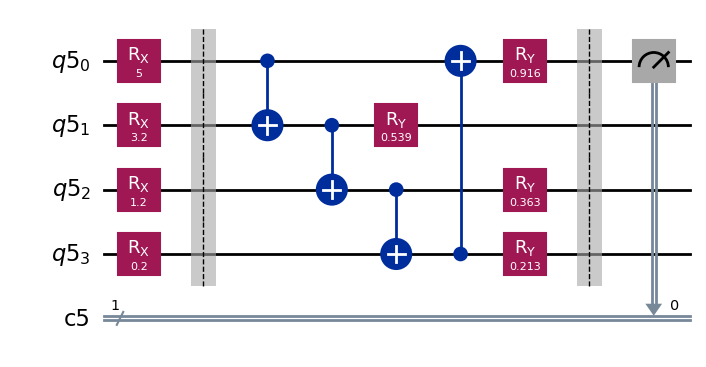

In [ ]:

qc, c =feature_map(X_train[5])

qc.barrier()

qc = variational_circuit(qc, np.random.rand(N))

qc.barrier()

# measurement operator
qc.measure(0,c)

# Devreyi çizelim 
qc.draw("mpl")



In [43]:
# Qiskit'in API değişikliklerine karşı dayanıklı ve güvenli bir yaklaşım
# StatevectorSampler kullanarak kuantum devresini çalıştırıyoruz
sampler = StatevectorSampler()
job = sampler.run([qc])  # shots kaldırıldı - StatevectorSampler'da gereksiz
result = job.result()

# Doğru API erişimi - classical register ismini dinamik bul
pub_result = result[0]
data_keys = list(pub_result.data.__dict__.keys())  # Classical register isimlerini bul
register_name = data_keys[0]  # İlk classical register'ı al
counts = getattr(pub_result.data, register_name).get_counts()

# Olasılık hesaplama
total_shots = sum(counts.values())
p1 = counts.get('1', 0) / total_shots

print(counts)   # {'0': ..., '1': ...}  Her ölçüm sonucunun kaç kez gözlendiği
print(p1)       # p1: '1' durumunun olasılık değeri (0.0 - 1.0 arası)

{'1': 637, '0': 387}
0.6220703125


In [42]:
print(Y_train[5])

0


Yukarıda kuantum devresinin tahmini (değerler değişse de) 1 çıktı ama gerçekte 0, bunun sebebi henüz açıları eğitmedik(thetas), şu an sadece normal değerli

In [37]:
def quantum_nn(X, theta, simulator=True):
    """
    Quantum Neural Network fonksiyonu
    
    Parameters:
    - X: Input features (numpy array)
    - theta: Variational parameters (numpy array)
    - simulator: Boolean (şu an kullanılmıyor ama gelecekte farklı backend'ler için)
    
    Returns:
    - p1: '1' durumunun olasılığı (float, 0-1 arası)
    """

    qc, c = feature_map(X) # # Feature map ile input'u kuantum devresine encode et
    qc = variational_circuit(qc, theta) ## Variational circuit ile learnable parametreleri ekle
    qc.measure(0,c) # # İlk qubit'i ölç
    sampler = StatevectorSampler()
    job = sampler.run([qc])  # shots kaldırıldı - StatevectorSampler'da gereksiz
    result = job.result()
    
    # Doğru API erişimi - classical register ismini dinamik bul
    pub_result = result[0]
    data_keys = list(pub_result.data.__dict__.keys())  # Classical register isimlerini bul
    register_name = data_keys[0]  # İlk classical register'ı al
    counts = getattr(pub_result.data, register_name).get_counts()

    # Olasılık hesaplama
    total_shots = sum(counts.values())
    p1 = counts.get('1', 0) / total_shots

    return p1

In [ ]:
# LOSS Fonksiyonu

def loss(prediction, target):
    """Mean Squared Error loss"""
    return (target - prediction)**2


# Burada loss olarak MSE kullanıldı ama BCE de kullanılabilirmiş

| Özellik      | MSE                                                              | BCE                                                                                           |
| ------------ | ---------------------------------------------------------------- | --------------------------------------------------------------------------------------------- |
| Çıktı tipi   | Sayısal değer (regresyon için doğal)                             | Olasılık değeri (0–1 arası)                                                                   |
| Problem tipi | Regresyon, bazen sınıflandırmada yanlış kullanılır               | İkili sınıflandırma için özel olarak tasarlanmış                                              |
| Cezalandırma | Hataları **kuadratik** cezalandırır (büyük hatalara çok duyarlı) | Yanlış sınıfa yüksek olasılık verildiğinde **logaritmik** olarak cezalandırır (çok daha sert) |
| Optimizasyon | Küçük gradyanlar → sigmoid/tanh çıktısında öğrenme yavaşlar      | Gradyanlar daha stabil, olasılık tabanlı öğrenme daha hızlı                                   |


### Stochastic Gradient Descent (SGD): 

Amaç kayıp fonksiyonunu (loss) 𝐿(𝜃) küçültmek.

Bunun için parametre vektörünü (𝜃: devredeki RY açıları) adım adım güncelliyoruz.

Her tek eğitim örneği için ileri geçiş (prediction) yap, kaybı hesapla, hemen güncelle. (Yani örnek başına güncelleme.)

* Mini-batch: 16–64 gibi küçük gruplarla aynı işlemi yap.
* Full-batch: Tüm eğitim setinin ortalamasını alıp epoch başına bir kez güncelle.

* Döngü: örnek → prediction → loss → gradient → θ güncelle. olarak ilerliyor

Eta (η): güncelleme adımı; hiperparametredir, model öğrenmez—sen seçersin.

In [ ]:
def gradient(X, Y, theta):
    """Tek sample için finite difference gradient"""
    delta = 0.01
    grad = []
    
    for i in range(len(theta)):
        # Parametreyi artır
        theta_plus = theta.copy()
        theta_plus[i] += delta
        
        # İki prediction hesapla
        pred_plus = quantum_nn(X, theta_plus)
        pred_original = quantum_nn(X, theta)
        
        # Finite difference
        loss_plus = loss(pred_plus, Y)
        loss_original = loss(pred_original, Y)
        gradient_i = (loss_plus - loss_original) / delta
        
        grad.append(gradient_i)
    
    return np.array(grad) 

* Loss: Hata ölçer → azaltmak istiyoruz.

* Gradyan: Hatanın yönünü ve şiddetini söyler → doğru güncelleme.

* Finite difference: Basit, her yerde çalışır (Kullandığımız).

In [ ]:
# ACCURACY Fonksiyonu

def accuracy(X, Y, theta):
    """
    İkili (binary) sınıflandırma için doğruluk (accuracy) hesaplar.

    Her örnek X_i için quantum_nn(X_i, theta) çağrılır ve p1 = P(qubit0=1) ∈ [0,1]
    elde edilir. Eşik 0.5 kullanılarak sınıf tahmini yapılır:
      - p1 < 0.5  → 0
      - p1 ≥ 0.5  → 1
    Tahmin ile gerçek etiket (Y_i ∈ {0,1}) eşleşirse sayaç artırılır.
    Sonuç: doğru_tahmin_sayısı / toplam_örnek.

    Notlar:
    - Bu fonksiyon X ve Y üzerinde `zip` ile dolaşır. `zip(X, Y)` kısa olana kadar iterasyon yapar;
      uzunluk uyuşmazlıklarını yakalamak için çağrı öncesi `assert len(X) == len(Y)` eklemek önerilir.
    - Statevector tabanlı tahminler deterministiktir (shots gerekmez).
      Aer/gerçek donanımda ölçüm istatistiğine (shots) bağlı olarak sonuçlar küçük dalgalanmalar gösterebilir.
    - Zaman maliyeti, her örnek için `quantum_nn` çağrısından gelir (O(n)); asıl yavaşlık burada oluşur.

    Parametreler
    ----------
    X : array-like, shape (n_samples, n_features)
        Özellik vektörleri.
    Y : array-like, shape (n_samples,)
        Gerçek etiketler (0 veya 1).
    theta : array-like
        Variational devrenin öğrenilebilir parametreleri.

    Döndürür
    -------
    float
        0 ile 1 arasında accuracy.
    """
    counter = 0
    
    for X_i, Y_i in zip(X, Y):
        prediction = quantum_nn(X_i, theta)
        
        # Binary classification: 0.5 threshold
        if prediction < 0.5 and Y_i == 0:
            counter += 1
        elif prediction >= 0.5 and Y_i == 1:
            counter += 1
    
    return counter / len(Y)

* Statevector (gürültüsüz) kullanıyorsan accuracy stabildir.

* Aer (shots) kullanıyorsan sonuçlar stokastik; doğruluk için shots’ı artır (örn. 10k) ya da aynı modeli birkaç kez ölçüp ortalama al.


## train_simple_qnn(...)

### Amaç:
  QNN’in parametrelerini (theta) SGD mantığıyla eğitmek ve her epoch sonunda
  loss / train accuracy / test accuracy değerlerini raporlamak.

### Girdiler:
  X_train, Y_train, X_test, Y_test : veri ve etiketler (binary 0/1)
  epochs : kaç kez tüm eğitim verisi üzerinden geçileceği
  eta    : öğrenme oranı (learning rate, hiperparametre)

### Adımlar:
1) Başlatma:
   - theta = np.ones(N): Parametreleri 1’lerle başlatır (tutorial uyumlu).
   - history listeleri: loss, train_acc, test_acc kaydı için boş listeler.

2) Epoch döngüsü (epochs kez):
   - loss_tmp = []: Bu epoch’taki örnek-başı loss’ları toplayacağız.
   - Eğitim örnekleri üzerinde tek tek dolaş:
       a) prediction = quantum_nn(X_i, theta)   # ileri geçiş, p(|1⟩)
       b) current_loss = loss(prediction, Y_i)  # (p − y)^2
          -> loss_tmp.append(current_loss)
       c) grad = gradient(X_i, Y_i, theta)      # finite difference ile ∂L/∂theta
       d) theta = theta − eta * grad            # gradient descent güncellemesi
     (Bu kısım örnek-bazlı güncelleme olduğu için “stochastic” karakterdedir.)

   - Epoch sonunda:
       avg_loss = mean(loss_tmp)                # o epoch’un ortalama MSE’si
       train_acc = accuracy(X_train, Y_train, theta)  # 0.5 eşik ile doğruluk
       test_acc  = accuracy(X_test,  Y_test,  theta)

   - Kayıt ve çıktı:
       loss_list.append(avg_loss), train_acc_list.append(train_acc), test_acc_list.append(test_acc)
       print(...) ile tablo satırı (epoch, loss, train/test acc) yazdırılır.

3) Dönüş:
   return theta, loss_list, train_acc_list, test_acc_list
   -> En son öğrenilmiş parametreler ve eğitim seyri (plot için) döner.

### Notlar:
- quantum_nn her çağrıda devreyi çalıştırdığı için eğitim yavaştır.
- gradient finite-difference ile hesaplandığından her parametre için ekstra ileri geçiş gerekir.
- eta çok büyükse dalgalanır, çok küçükse yavaş öğrenir (hiperparametre ayarı önemlidir).
"""


In [ ]:
# TRAINING LOOP

def train_simple_qnn(X_train, Y_train, X_test, Y_test, epochs=20, eta=0.05):
    """
    Basit QNN training
    """
    # Başlangıç parametreleri
    theta = np.ones(N)  # Tutorial gibi ones ile başla
    
    # Training history
    loss_list = []
    train_acc_list = []
    test_acc_list = []
    
    print("Epoch \t Loss \t Training Acc \t Test Acc")
    print("-" * 50)
    
    for epoch in range(epochs):
        loss_tmp = []
        
        # Her training sample için
        for X_i, Y_i in zip(X_train, Y_train):
            # Forward pass
            prediction = quantum_nn(X_i, theta)
            
            # Loss hesapla
            current_loss = loss(prediction, Y_i)
            loss_tmp.append(current_loss)
            
            # Gradient hesapla ve theta güncelle
            grad = gradient(X_i, Y_i, theta)
            theta = theta - eta * grad  # Gradient descent rule
        
        # Epoch istatistikleri
        avg_loss = np.mean(loss_tmp)
        train_acc = accuracy(X_train, Y_train, theta)
        test_acc = accuracy(X_test, Y_test, theta)
        
        # Kaydet
        loss_list.append(avg_loss)
        train_acc_list.append(train_acc)
        test_acc_list.append(test_acc)
        
        # Progress yazdır
        print(f"{epoch:5d} \t {avg_loss:.3f} \t {train_acc:11.3f} \t {test_acc:8.3f}")
    
    return theta, loss_list, train_acc_list, test_acc_list


In [47]:
optimal_theta, losses, train_accs, test_accs = train_simple_qnn(
    X_train, Y_train, X_test, Y_test, epochs=20, eta=0.05
)


Epoch 	 Loss 	 Training Acc 	 Test Acc
--------------------------------------------------
    0 	 0.219 	       0.836 	    0.758
    1 	 0.203 	       0.821 	    0.697
    2 	 0.204 	       0.821 	    0.758
    3 	 0.198 	       0.791 	    0.848
    4 	 0.204 	       0.791 	    0.727
    5 	 0.224 	       0.761 	    0.636
    6 	 0.233 	       0.284 	    0.333
    7 	 0.307 	       0.194 	    0.242
    8 	 0.305 	       0.179 	    0.273
    9 	 0.303 	       0.179 	    0.303
   10 	 0.294 	       0.299 	    0.273
   11 	 0.282 	       0.254 	    0.273
   12 	 0.286 	       0.209 	    0.303
   13 	 0.243 	       0.821 	    0.788
   14 	 0.235 	       0.806 	    0.758
   15 	 0.213 	       0.806 	    0.879
   16 	 0.207 	       0.791 	    0.818
   17 	 0.207 	       0.776 	    0.818
   18 	 0.222 	       0.821 	    0.788
   19 	 0.215 	       0.866 	    0.697


In [ ]:
# VISUALIZATION


def plot_training_simple(loss_list, train_acc_list, test_acc_list):
    """
    Training sonuçlarını görselleştir
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    # Loss plot
    ax1.plot(loss_list, 'b-', linewidth=2, label='Training Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss (MSE)')
    ax1.set_title('Training Loss Over Time')
    ax1.grid(True, alpha=0.3)
    ax1.legend()
    
    # Accuracy plot
    ax2.plot(train_acc_list, 'g-', linewidth=2, label='Training Accuracy')
    ax2.plot(test_acc_list, 'r-', linewidth=2, label='Test Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.set_title('Accuracy Over Time')
    ax2.grid(True, alpha=0.3)
    ax2.legend()
    ax2.set_ylim([0, 1])
    
    plt.tight_layout()
    plt.show()

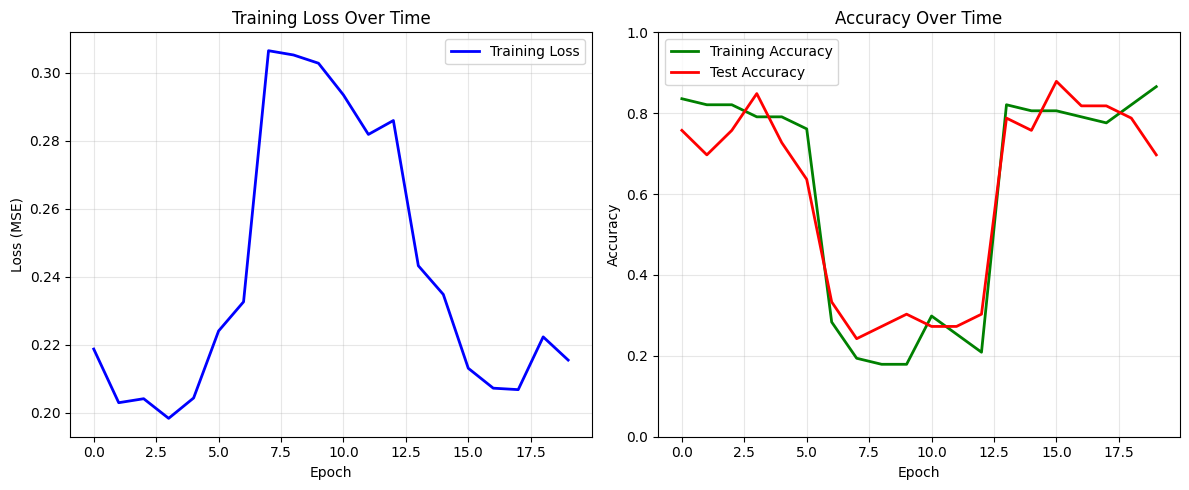

In [49]:
plot_training_simple(losses, train_accs, test_accs)


Simple QNN Training (Tutorial Method)
Epoch 	 Loss 	 Training Acc 	 Test Acc
--------------------------------------------------
    0 	 0.297 	       0.194 	    0.152
    1 	 0.310 	       0.224 	    0.303
    2 	 0.309 	       0.194 	    0.212
    3 	 0.315 	       0.224 	    0.212
    4 	 0.300 	       0.343 	    0.515
    5 	 0.291 	       0.179 	    0.121
    6 	 0.251 	       0.567 	    0.455
    7 	 0.213 	       0.791 	    0.727
    8 	 0.203 	       0.791 	    0.697
    9 	 0.215 	       0.806 	    0.758
   10 	 0.227 	       0.597 	    0.576
   11 	 0.227 	       0.761 	    0.818
   12 	 0.236 	       0.597 	    0.545
   13 	 0.223 	       0.836 	    0.758
   14 	 0.217 	       0.776 	    0.758
   15 	 0.205 	       0.806 	    0.758
   16 	 0.202 	       0.791 	    0.727
   17 	 0.207 	       0.806 	    0.667
   18 	 0.222 	       0.791 	    0.758
   19 	 0.205 	       0.791 	    0.818

 Training Completed!
Final Training Accuracy: 0.791
Final Test Accuracy: 0.818
Final Loss: 

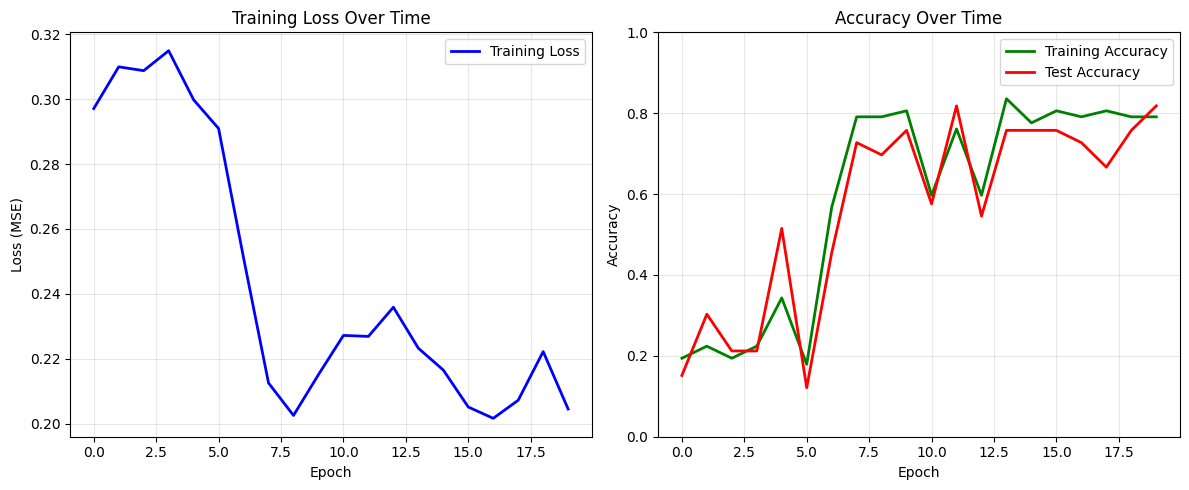


 Sample Test Predictions:
Sample 1: Pred=0.509 → Class=1, Actual=1
Sample 2: Pred=0.556 → Class=1, Actual=1
Sample 3: Pred=0.502 → Class=1, Actual=1
Sample 4: Pred=0.440 → Class=0, Actual=0
Sample 5: Pred=0.589 → Class=1, Actual=0


In [ ]:
# ÇALIŞTIRILACAK KOD


if __name__ == "__main__":
    print("Simple QNN Training (Tutorial Method)")
    print("=" * 60)
    
    # Hyperparameters
    N = 4  # Feature count
    eta = 0.05  # Learning rate
    epochs = 20
    
    # Training başlat
    optimal_theta, losses, train_accs, test_accs = train_simple_qnn(
        X_train, Y_train, X_test, Y_test, 
        epochs=epochs, eta=eta
    )
    
    print(f"\n Training Completed!")
    print(f"Final Training Accuracy: {train_accs[-1]:.3f}")
    print(f"Final Test Accuracy: {test_accs[-1]:.3f}")
    print(f"Final Loss: {losses[-1]:.3f}")
    
    # Sonuçları görselleştir
    plot_training_simple(losses, train_accs, test_accs)
    
    # Final predictions
    print(f"\n Sample Test Predictions:")
    for i in range(5):
        pred = quantum_nn(X_test[i], optimal_theta)
        actual = Y_test[i]
        predicted_class = 1 if pred >= 0.5 else 0
        print(f"Sample {i+1}: Pred={pred:.3f} → Class={predicted_class}, Actual={actual}")